In [493]:
import numpy as np 
import matplotlib.pyplot as plt
import control as ct
import scipy.signal as signal
import math

In [494]:
K = 5
G1 = ct.tf([1], [1, 0])
G2 = ct.tf([1], [1, 2])
G3 = ct.tf([1], [1, 5])
G4 = ct.tf([1], [1, 6])

# Gain of the system K 
print(f'The gain of the system K: {K}')

# Actual Plant 
G = K * G1 * G2 * G3 * G4
print(f'The transfer function of the system G(s): {G}')

# Feedback Loop Transfer Function
H = 1 
print(f'The transfer function of the feedback loop H(s): {H}')

# Open Loop Transfer Funtion 
L = G * H
print(f'The transfer function of the open loop system L(s): {L}')

# Closed Loop Transfer Funtion
CL = ct.feedback(G, H)
print(f'The transfer function of the closed loop system CL(s): {CL}')

The gain of the system K: 5
The transfer function of the system G(s): <TransferFunction>: sys[985]
Inputs (1): ['u[0]']
Outputs (1): ['y[0]']

               5
  ----------------------------
  s^4 + 13 s^3 + 52 s^2 + 60 s
The transfer function of the feedback loop H(s): 1
The transfer function of the open loop system L(s): <TransferFunction>: sys[987]
Inputs (1): ['u[0]']
Outputs (1): ['y[0]']

               5
  ----------------------------
  s^4 + 13 s^3 + 52 s^2 + 60 s
The transfer function of the closed loop system CL(s): <TransferFunction>: sys[989]
Inputs (1): ['u[0]']
Outputs (1): ['y[0]']

                 5
  --------------------------------
  s^4 + 13 s^3 + 52 s^2 + 60 s + 5


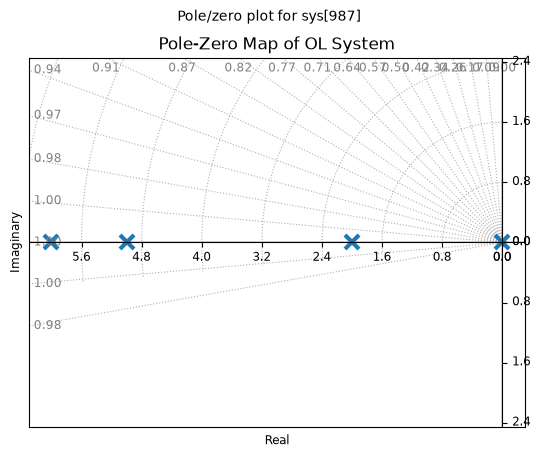

Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.


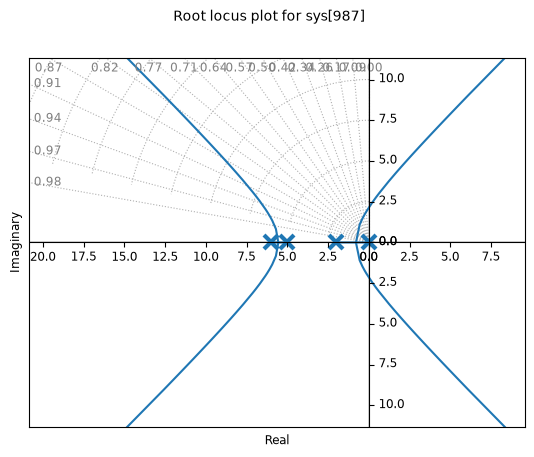

DC gain for OL= inf
Zeros of OL= []
Poles of OL= [-6.+0.j -5.+0.j -2.+0.j  0.+0.j]
Dominant stable OL pole(s): [-2.+0.j]
Dominant OL pole (p1) = (-2.0000000000000027+0j)
Dominant OL pole (p1) in abs value = 2.0000000000000027


In [495]:
# Plot the Pole-Zero map with the damping/frequency grid
ct.pole_zero_plot(L, grid=True, marker_size=10, marker_width=3)
plt.title("Pole-Zero Map of OL System")
plt.show()

# Root locus = drawn for open loop system to see closed loop poles location at s plane
ct.root_locus(L, grid=True, marker_size=10, marker_width=3) 
plt.show()

# DC gain 
dc = ct.dcgain(L)
print(f'DC gain for OL= {dc}')
# Zeros 
z = ct.zeros(L)
print(f'Zeros of OL= {z}')
# Poles 
p = ct.poles(L)
print(f'Poles of OL= {p}')

tol = 1e-8
# keep only strictly stable poles (real part < 0)
stable_mask = np.real(p) < -tol

if np.any(stable_mask):
    p_stable = p[stable_mask]
    rp = np.real(p_stable)
    max_rp = np.max(rp)
    dominant_poles = p_stable[np.isclose(rp, max_rp, atol=tol)]
else:
    dominant_poles = np.array([])
    print("No strictly stable pole -> no classical dominant pole.")

print("Dominant stable OL pole(s):", dominant_poles)

p1 = dominant_poles[0]
print(f'Dominant OL pole (p1) = {p1}')
print(f'Dominant OL pole (p1) in abs value = {np.abs(p1)}')

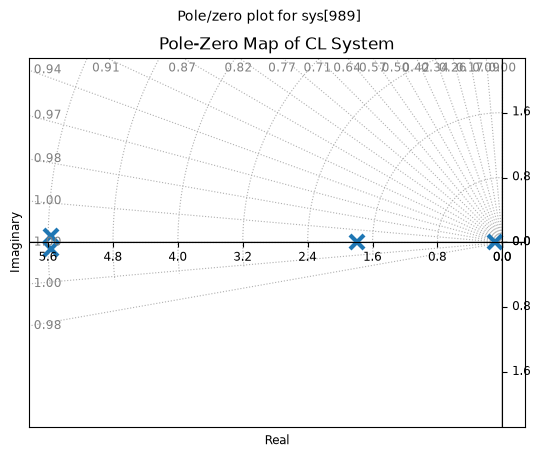

DC gain for CL= 1.0
Zeros of CL= []
Poles of CL= [-5.55822874+0.0772007j -5.55822874-0.0772007j -1.7933111 +0.j
 -0.09023141+0.j       ]
    Eigenvalue (pole)       Damping     Frequency
    -5.558   +0.0772j        0.9999         5.559
    -5.558   -0.0772j        0.9999         5.559
               -1.793             1         1.793
             -0.09023             1       0.09023
Natural frequency of poles (Wn) = [5.55876485 5.55876485 1.7933111  0.09023141]
Damping ratio zeta of poles (Z) = [0.99990356 0.99990356 1.         1.        ]
Poles = [-5.55822874+0.0772007j -5.55822874-0.0772007j -1.7933111 +0.j
 -0.09023141+0.j       ]
Poles of CL= [-5.55822874+0.0772007j -5.55822874-0.0772007j -1.7933111 +0.j
 -0.09023141+0.j       ]
Dominant stable CL pole(s): [-0.09023141+0.j]
Dominant CL pole (p1) = (-0.09023141351629041+0j)
Dominant CL pole (p1) in abs value = 0.09023141351629041


Dominant Pole: (-0.09023141351629041+0j)
Natural frequency (wn): 0.09023141351629041 rad/s
Damping ra

In [496]:
# closed loop poles and zeros analysis 

# Plot the Pole-Zero map with the damping/frequency grid
ct.pole_zero_plot(CL, grid=True, marker_size=10, marker_width=3)
plt.title("Pole-Zero Map of CL System")
plt.show()

# DC gain 
dc = ct.dcgain(CL)
print(f'DC gain for CL= {dc}')
# Zeros 
z = ct.zeros(CL)
print(f'Zeros of CL= {z}')
# Poles 
p = ct.poles(CL)
print(f'Poles of CL= {p}')

# Print exact transient metrics derived from poles 
wn, zeta, poles = ct.damp(CL)
print(f'Natural frequency of poles (Wn) = {wn}')
print(f'Damping ratio zeta of poles (Z) = {zeta}')
print(f'Poles = {poles}')

# To find the dominant pole(s) of a control system plant, 
# you identify the poles (the roots of the denominator of the transfer function) that lie closest to the imaginary (jw) axis 
# or the origin in the s-plane, 
# provided other poles are sufficiently far away
print(f'Poles of CL= {p}')

tol = 1e-8
# keep only strictly stable poles (real part < 0)
stable_mask = np.real(p) < -tol

if np.any(stable_mask):
    p_stable = p[stable_mask]
    rp = np.real(p_stable)
    max_rp = np.max(rp)
    dominant_poles = p_stable[np.isclose(rp, max_rp, atol=tol)]
else:
    dominant_poles = np.array([])
    print("No strictly stable pole -> no classical dominant pole.")

print("Dominant stable CL pole(s):", dominant_poles)

p1 = dominant_poles[0]
print(f'Dominant CL pole (p1) = {p1}')
print(f'Dominant CL pole (p1) in abs value = {np.abs(p1)}')
print('\n')

wn = abs(p1)                  # Natural frequency (rad/s)
zeta = -np.real(p1) / wn     # Damping ratio
sigma = -np.real(p1)         # Decay rate (1/s)
wd = abs(np.imag(p1))        # Damped frequency (rad/s)

print("Dominant Pole:", p1)
print("Natural frequency (wn):", wn, "rad/s")
print("Damping ratio (zeta, z):", zeta)
print("Decay rate (sigma):", sigma, "1/s")
print("Damped frequency (wd):", wd, "rad/s")




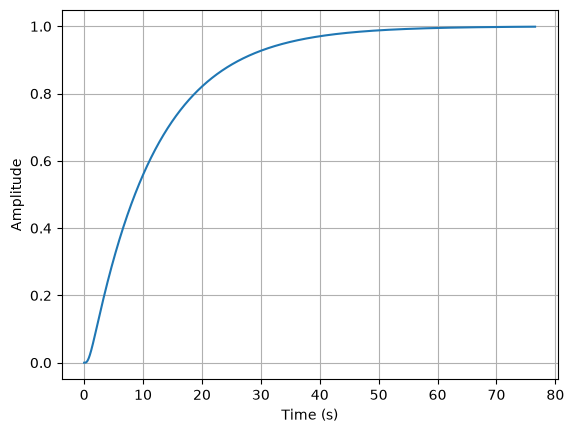

Rise Time (Tr): 24.38 seconds
Settling Time (Ts): 44.29 seconds
Peak Time (Tp): 76.56 seconds
Overshoot (%): 0.00%
Final Value = 1.0
Steasy state error (ess) = 0.0


In [497]:
plt.figure()
t, y = ct.step_response(CL)

plt.plot(t, y)
plt.xlabel('Time (s)')
plt.ylabel('Amplitude')
plt.grid(True)
plt.show()

# transient characteristics
info = ct.step_info(CL)
final_value = info['SteadyStateValue']
ess = 1 - final_value


print(f"Rise Time (Tr): {info['RiseTime']:.2f} seconds")
print(f"Settling Time (Ts): {info['SettlingTime']:.2f} seconds")
print(f"Peak Time (Tp): {info['PeakTime']:.2f} seconds")
print(f"Overshoot (%): {info['Overshoot']:.2f}%")
# print(f"Undershoot (%): {info['Undershoot']:.2f}%")
print(f'Final Value = {info["SteadyStateValue"]}')
print(f'Steasy state error (ess) = {ess}')

In [498]:
# Required Specification 

# Settling time (Ts) <= 2 seconds
# Maximum Overshoot (Mp) <= 5%

# Ts = 4/(zeta * wn) => wn = 4/(zeta * Ts)
# Mp = exp((-zeta * pi)/sqrt(1 - zeta^2)) => zeta = sqrt((ln(Mp))^2 / ((ln(Mp))^2 + pi^2))

In [499]:
Ts = 5
Mp = 0.01

# Maximum overshoot (Mp) = exp((-zeta * pi)/sqrt(1 - zeta^2))
# zeta = sqrt((ln(Mp))^2 / ((ln(Mp))^2 + pi^2))
zeta = np.sqrt((np.log(Mp))**2 / ((np.log(Mp))**2 + np.pi**2))

# Settling Time (Ts) ~ 4/(zeta * wn)
wn = 4/(zeta * Ts)
wd = wn * np.sqrt(1 - zeta**2)

# s = a + bj
a = -zeta * wn
b = wd 
Sd = a + b*1j
# Sd = -2 + 4*1j

print(f'Required Damping Ratio (zeta) = {zeta}')
print(f'Required Natural Frequency (wn) = {wn}')
print(f'Required Damped Frequency (wd) = {wd}')
print(f'Required Dominant Pole (Sd) = {Sd}')
print(f'Required Dominant pole in abs value (Sd) = {np.abs(Sd)}')

Required Damping Ratio (zeta) = 0.8260850546139571
Required Natural Frequency (wn) = 0.9684232822416246
Required Damped Frequency (wd) = 0.5457505415367365
Required Dominant Pole (Sd) = (-0.8+0.5457505415367365j)
Required Dominant pole in abs value (Sd) = 0.9684232822416246


In [500]:
# # Let zeta = 0.5
# # Natural Frequency (wn) = 3 rad/s
# zeta = 0.5
# wn = 3

# Sd = -(zeta*wn)+1j*wn*np.sqrt(1-zeta**2)
# print(f'Required Dominant Pole (Sd) = {Sd}')
# print(f'Required Dominant Pole in absolute form (Sd) = {np.abs(Sd)}')

In [501]:
# So alone Gain Adujustment cannot alone achieve the desired performance
# as real part of dominant pole = -3 and root locus can only provide real part of poles = -0.5 

In [502]:
# Angle dificiency = 180 - angle(zeros) + angle(poles)
phi = np.rad2deg(np.angle(G(Sd))) - 180
print(f'Angle Deficiency phi = {phi}')

# Deficit angle must be contributed by a lead compensator.
phi_c = -phi
print(f'Angle that must be contributed by lead compensator = {phi_c}')

Angle Deficiency phi = -3.5492601987748174
Angle that must be contributed by lead compensator = 3.5492601987748174


In [503]:
# Choose zero of the lead compensator to cancle the real dominant pole (not complex) of the open or closed loop system
zc = 2
print(f'Lead Compensator Zero (zc) = {zc}')

# So lead compensator pole must be at required dominant pole 
# pc = np.abs(Sd)
# print(f'Lead Compensator Pole (pc) = {pc}')

# And also it comes from angle criteria i.e. angle(G * H) = 180 
# angle(zeros) - angle(poles) = 180  
# Or for lead compensator angle(zeros) - angle(poles) = angle deficiency 

w = np.rad2deg(np.angle(Sd + zc)) - phi_c
print(f'for compensator angle(zeros) - angle deficiency (w) = {w}')
v = np.tan(np.deg2rad(w))
print(f'tan of tan of w (v) = {v}')

pc = (np.imag(Sd)/v) - np.real(Sd)
print(f'pole of lead compensator = {pc}')

# Lead Compensator transfer function without gain 
Gc = ct.tf([1, zc], [1, pc])
print(f'Lead Compensator Transfer Function without gain (Gc) = {Gc}')

print(f'Open Loop Gain at required Pole Gc(Sd) = {Gc(Sd)}')
print(f'Open Loop Gain at required Pole in absolute form Gc(Sd) = {np.abs(Gc(Sd))}')
print(f'Open Loop Phase at required Pole Gc(Sd) = {np.angle(Gc(Sd))}')
print(f'Open Loop Phase at required Pole in Degrees Gc(Sd) = {np.rad2deg(np.angle(Gc(Sd)))}')

Lead Compensator Zero (zc) = 2
for compensator angle(zeros) - angle deficiency (w) = 20.906406269914292
tan of tan of w (v) = 0.3819909875158825
pole of lead compensator = 2.2287000462649535
Lead Compensator Transfer Function without gain (Gc) = <TransferFunction>: sys[994]
Inputs (1): ['u[0]']
Outputs (1): ['y[0]']

    s + 2
  ---------
  s + 2.229
Open Loop Gain at required Pole Gc(Sd) = (0.8603078544129281+0.05336114064101797j)
Open Loop Gain at required Pole in absolute form Gc(Sd) = 0.8619611451191326
Open Loop Phase at required Pole Gc(Sd) = 0.06194627647860904
Open Loop Phase at required Pole in Degrees Gc(Sd) = 3.5492601987748214


In [504]:
# Lead compensator gain 
Kc = 1/(np.abs(G(Sd)*Gc(Sd)))
print(f'Lead Compensator Gain (Kc) = {Kc}')

Lead Compensator Gain (Kc) = 6.559641792802635


In [505]:
Gc1 = Kc * Gc
print(f'Lead Compensator Transfer Function with gain (Gc1) = {Gc1}')

print(f'Open Loop Gain at required Pole G(Sd) = {Gc(Sd)}')
print(f'Open Loop Gain at required Pole in absolute form G(Sd) = {np.abs(Gc(Sd))}')
print(f'Open Loop Phase at required Pole G(Sd) = {np.angle(Gc(Sd))}')
print(f'Open Loop Phase at required Pole in Degrees G(Sd) = {np.rad2deg(np.angle(Gc(Sd)))}')

Lead Compensator Transfer Function with gain (Gc1) = <TransferFunction>: sys[996]
Inputs (1): ['u[0]']
Outputs (1): ['y[0]']

  6.56 s + 13.12
  --------------
    s + 2.229
Open Loop Gain at required Pole G(Sd) = (0.8603078544129281+0.05336114064101797j)
Open Loop Gain at required Pole in absolute form G(Sd) = 0.8619611451191326
Open Loop Phase at required Pole G(Sd) = 0.06194627647860904
Open Loop Phase at required Pole in Degrees G(Sd) = 3.5492601987748214


In [506]:
A1 = K*G2*G3*G4*Gc1 
# Type of system = 1 i.e. pole at origin = 1 
# so the velocity error constant, Kv = lim:s->0 sG(s)Gc(s)
kv = np.abs(A1(0))
print(f'velocity error constant kv = {kv}')

ess = 1/kv
print(f'steady state error ess = {ess}')

velocity error constant kv = 0.49054319084615006
steady state error ess = 2.0385564791452415


In [507]:
A2 = G*Gc1 
print(f'System Transfer Function with compensator A2(s) = {A2}')
A3 = A2 * H
print(f'open loop system transfer function with compensator A3(s) = {A3}')
A4 = ct.feedback(A2, 1)
print(f'Closed loop system transfer function with compensator A4(s) = {A4}')

System Transfer Function with compensator A2(s) = <TransferFunction>: sys[1002]
Inputs (1): ['u[0]']
Outputs (1): ['y[0]']

                    32.8 s + 65.6
  -------------------------------------------------
  s^5 + 15.23 s^4 + 80.97 s^3 + 175.9 s^2 + 133.7 s
open loop system transfer function with compensator A3(s) = <TransferFunction>: sys[1004]
Inputs (1): ['u[0]']
Outputs (1): ['y[0]']

                    32.8 s + 65.6
  -------------------------------------------------
  s^5 + 15.23 s^4 + 80.97 s^3 + 175.9 s^2 + 133.7 s
Closed loop system transfer function with compensator A4(s) = <TransferFunction>: sys[1006]
Inputs (1): ['u[0]']
Outputs (1): ['y[0]']

                       32.8 s + 65.6
  --------------------------------------------------------
  s^5 + 15.23 s^4 + 80.97 s^3 + 175.9 s^2 + 166.5 s + 65.6


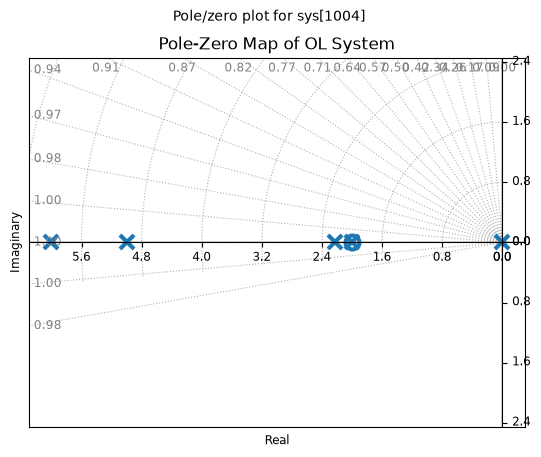

Ignoring fixed y limits to fulfill fixed data aspect with adjustable data limits.


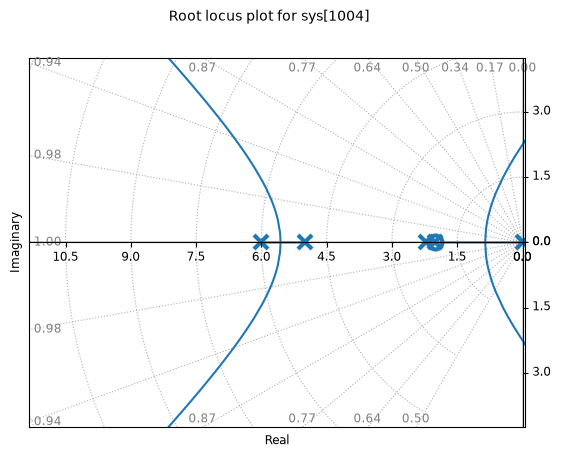

DC gain for OL= inf
Zeros of OL= [-2.+0.j]
Poles of OL= [-6.        +0.j -5.        +0.j -2.22870005+0.j -2.        +0.j
  0.        +0.j]
Dominant stable OL pole(s): [-2.+0.j]
Dominant OL pole (p1) = (-2.000000000000077+0j)
Dominant OL pole (p1) in abs value = 2.000000000000077


In [508]:
# Plot the Pole-Zero map with the damping/frequency grid
ct.pole_zero_plot(A3, grid=True, marker_size=10, marker_width=3)
plt.title("Pole-Zero Map of OL System")
plt.show()

# Root locus = drawn for open loop system to see closed loop poles location at s plane
ct.root_locus(A3, grid=True, marker_size=10, marker_width=3) 
plt.show()

# DC gain 
dc = ct.dcgain(A3)
print(f'DC gain for OL= {dc}')
# Zeros 
z = ct.zeros(A3)
print(f'Zeros of OL= {z}')
# Poles 
p = ct.poles(A3)
print(f'Poles of OL= {p}')

tol = 1e-8
# keep only strictly stable poles (real part < 0)
stable_mask = np.real(p) < -tol

if np.any(stable_mask):
    p_stable = p[stable_mask]
    rp = np.real(p_stable)
    max_rp = np.max(rp)
    dominant_poles = p_stable[np.isclose(rp, max_rp, atol=tol)]
else:
    dominant_poles = np.array([])
    print("No strictly stable pole -> no classical dominant pole.")

print("Dominant stable OL pole(s):", dominant_poles)

p1 = dominant_poles[0]
print(f'Dominant OL pole (p1) = {p1}')
print(f'Dominant OL pole (p1) in abs value = {np.abs(p1)}')

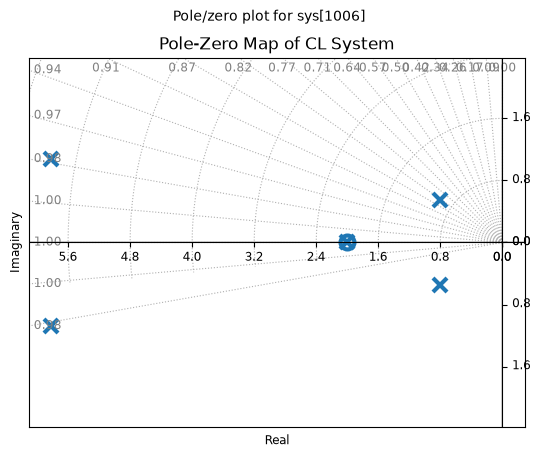

DC gain for CL= 1.0
Zeros of CL= [-2.+0.j]
Poles of CL= [-5.81435002+1.079477j   -5.81435002-1.079477j   -2.        +0.j
 -0.8       +0.54575054j -0.8       -0.54575054j]
    Eigenvalue (pole)       Damping     Frequency
    -5.814    +1.079j        0.9832         5.914
    -5.814    -1.079j        0.9832         5.914
                   -2             1             2
      -0.8   +0.5458j        0.8261        0.9684
      -0.8   -0.5458j        0.8261        0.9684
Natural frequency of poles (Wn) = [5.91370753 5.91370753 2.         0.96842328 0.96842328]
Damping ratio zeta of poles (Z) = [0.98319878 0.98319878 1.         0.82608505 0.82608505]
Poles = [-5.81435002+1.079477j   -5.81435002-1.079477j   -2.        +0.j
 -0.8       +0.54575054j -0.8       -0.54575054j]
Poles of CL= [-5.81435002+1.079477j   -5.81435002-1.079477j   -2.        +0.j
 -0.8       +0.54575054j -0.8       -0.54575054j]
Dominant stable CL pole(s): [-0.8+0.54575054j -0.8-0.54575054j]
Dominant CL pole (p1) = (-0.8000

In [509]:
# closed loop poles and zeros analysis 

# Plot the Pole-Zero map with the damping/frequency grid
ct.pole_zero_plot(A4, grid=True, marker_size=10, marker_width=3)
plt.title("Pole-Zero Map of CL System")
plt.show()

# DC gain 
dc = ct.dcgain(A4)
print(f'DC gain for CL= {dc}')
# Zeros 
z = ct.zeros(A4)
print(f'Zeros of CL= {z}')
# Poles 
p = ct.poles(A4)
print(f'Poles of CL= {p}')

# Print exact transient metrics derived from poles 
wn, zeta, poles = ct.damp(A4)
print(f'Natural frequency of poles (Wn) = {wn}')
print(f'Damping ratio zeta of poles (Z) = {zeta}')
print(f'Poles = {poles}')

# To find the dominant pole(s) of a control system plant, 
# you identify the poles (the roots of the denominator of the transfer function) that lie closest to the imaginary (jw) axis 
# or the origin in the s-plane, 
# provided other poles are sufficiently far away
print(f'Poles of CL= {p}')

tol = 1e-8
# keep only strictly stable poles (real part < 0)
stable_mask = np.real(p) < -tol

if np.any(stable_mask):
    p_stable = p[stable_mask]
    rp = np.real(p_stable)
    max_rp = np.max(rp)
    dominant_poles = p_stable[np.isclose(rp, max_rp, atol=tol)]
else:
    dominant_poles = np.array([])
    print("No strictly stable pole -> no classical dominant pole.")

print("Dominant stable CL pole(s):", dominant_poles)

p1 = dominant_poles[0]
print(f'Dominant CL pole (p1) = {p1}')
print(f'Dominant CL pole (p1) in abs value = {np.abs(p1)}')
print('\n')

wn = abs(p1)                  # Natural frequency (rad/s)
zeta = -np.real(p1) / wn     # Damping ratio
sigma = -np.real(p1)         # Decay rate (1/s)
wd = abs(np.imag(p1))        # Damped frequency (rad/s)

print("Dominant Pole:", p1)
print("Natural frequency (wn):", wn, "rad/s")
print("Damping ratio (zeta, z):", zeta)
print("Decay rate (sigma):", sigma, "1/s")
print("Damped frequency (wd):", wd, "rad/s")




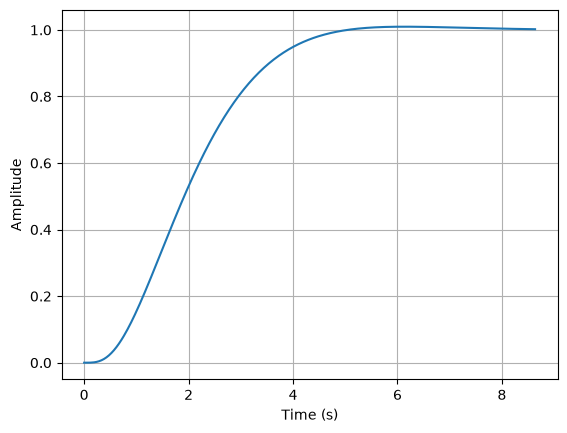

Rise Time (Tr): 2.73 seconds
Settling Time (Ts): 4.48 seconds
Peak Time (Tp): 6.14 seconds
Overshoot (%): 0.97%
Final Value = 1.0
Steasy state error (ess) = 0.0


In [510]:
plt.figure()
t, y = ct.step_response(A4)

plt.plot(t, y)
plt.xlabel('Time (s)')
plt.ylabel('Amplitude')
plt.grid(True)
plt.show()

# transient characteristics
info = ct.step_info(A4)
final_value = info['SteadyStateValue']
ess = 1 - final_value


print(f"Rise Time (Tr): {info['RiseTime']:.2f} seconds")
print(f"Settling Time (Ts): {info['SettlingTime']:.2f} seconds")
print(f"Peak Time (Tp): {info['PeakTime']:.2f} seconds")
print(f"Overshoot (%): {info['Overshoot']:.2f}%")
# print(f"Undershoot (%): {info['Undershoot']:.2f}%")
print(f'Final Value = {info["SteadyStateValue"]}')
print(f'Steasy state error (ess) = {ess}')

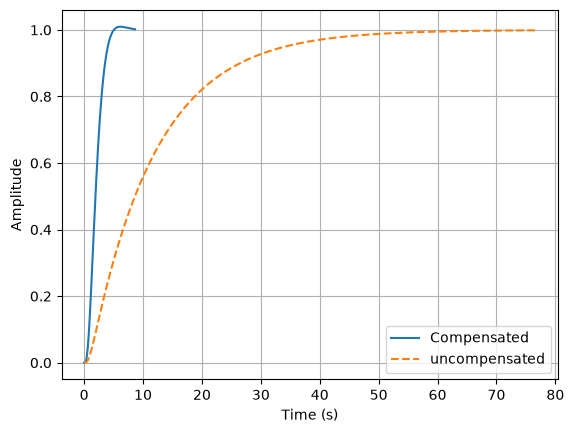

In [511]:
plt.figure()
t1, y1 = ct.step_response(A4)
t2, y2 = ct.step_response(CL)

plt.plot(t1, y1, label='Compensated')
plt.plot(t2, y2, label='uncompensated', linestyle='--')
plt.xlabel('Time (s)')
plt.ylabel('Amplitude')
plt.grid(True)
plt.legend()
plt.show()